In [1]:
import sys, json; sys.path.append("..")
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from src.train import make_lgbm

train = pd.read_csv("../data/processed/train.csv", index_col=0)
y = train.pop("SeriousDlqin2yrs"); X = train
best = json.load(open("../reports/best_lgbm_params.json"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba = cross_val_predict(make_lgbm(**best), X, y, cv=cv, method="predict_proba")[:, 1]

COST_FP, COST_FN = 1000, 6000
rows = []
for t in np.arange(0.05, 0.96, 0.05):          # try the dial at many positions
    flagged = proba >= t
    fp = (flagged & (y == 0)).sum()             # good borrowers we rejected
    fn = (~flagged & (y == 1)).sum()            # defaulters we missed
    rows.append((round(t, 2), fp, fn, fp * COST_FP + fn * COST_FN))

res = pd.DataFrame(rows, columns=["threshold", "FP", "FN", "cost"])
res.sort_values("cost").head(5)

,threshold,FP,FN,cost
13,0.70,9338,3276,28994000
12,0.65,11838,2896,29214000
14,0.75,7169,3726,29525000
11,0.60,14793,2534,29997000
15,0.80,5399,4196,30575000


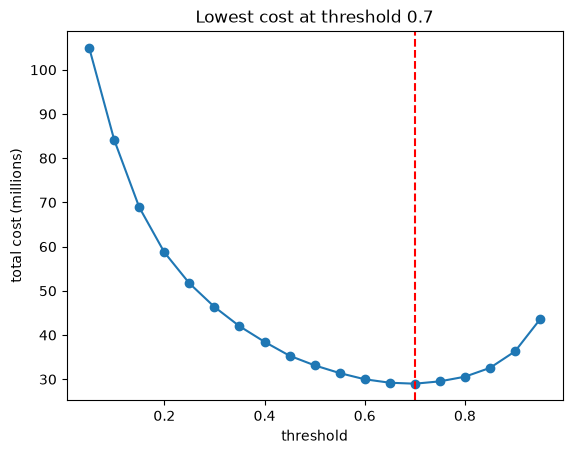

In [2]:
import matplotlib.pyplot as plt
import json

best_t = float(res.loc[res["cost"].idxmin(), "threshold"])   # row with the lowest cost

plt.plot(res["threshold"], res["cost"] / 1e6, marker="o")
plt.axvline(best_t, color="red", linestyle="--")
plt.xlabel("threshold"); plt.ylabel("total cost (millions)")
plt.title(f"Lowest cost at threshold {best_t}")
plt.show()

json.dump({"threshold": best_t}, open("../reports/threshold.json", "w"))